# Problem C11, page 9
(методичка по матстату)
https://classroom.google.com/w/ODc2NTc4MjM2MTUz/t/all


In [42]:
import numpy as np
from matplotlib import pyplot as plt

theta = 3.14

n = 1000

x = np.random.rand(n) * theta

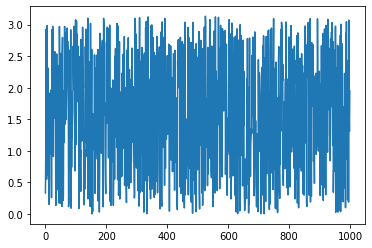

In [43]:
plt.plot(x)

(array([108.,  89.,  94., 100.,  98.,  98., 113.,  91., 111.,  98.]),
 array([2.19372796e-03, 3.15241191e-01, 6.28288655e-01, 9.41336118e-01,
        1.25438358e+00, 1.56743104e+00, 1.88047851e+00, 2.19352597e+00,
        2.50657343e+00, 2.81962090e+00, 3.13266836e+00]),
 <BarContainer object of 10 artists>)

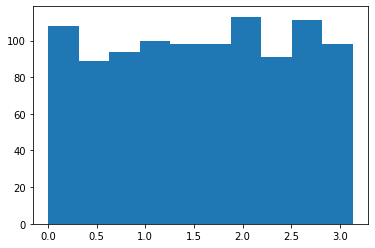

In [44]:
plt.hist(x)

In [45]:
est_theta_one = (n + 1) * x.min()
est_theta_two = (1 + 1 / n) * x.max()

In [46]:
est_theta_one, est_theta_two

(np.float64(2.195921688391598), np.float64(3.1358010294810277))

# Math expectation

In [77]:
n = 1000
N = 1000

x = np.random.rand(N, n) * theta
x.shape

(1000, 1000)

In [78]:
est_theta_one = (n + 1) * x.min(axis=1)
est_theta_one.shape

(1000,)

In [79]:
est_theta_two = (1 + 1 / n) * x.max(axis=1)
est_theta_two.shape

(1000,)

In [80]:
est_theta_one.mean()

np.float64(3.0850931301965785)

In [81]:
est_theta_two.mean()

np.float64(3.1400994058893894)

In [82]:
theta

3.14

In [83]:
est_theta_two.mean() - theta

np.float64(9.94058893892813e-05)

In [84]:
est_theta_one.mean() - theta

np.float64(-0.05490686980342163)

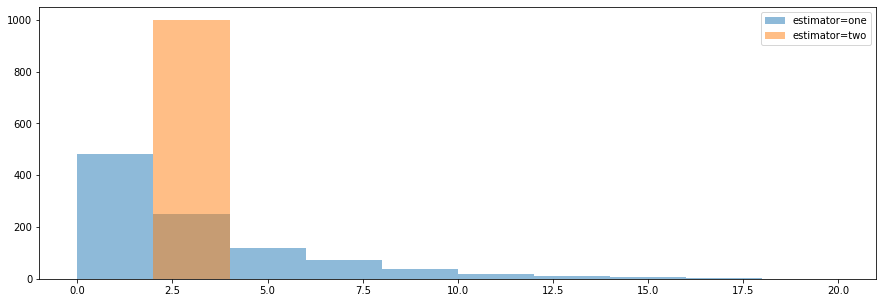

In [85]:
plt.figure(figsize=(15, 5))
_ = plt.hist(est_theta_one, label='estimator=one', range=(0, 20), bins=10, alpha=0.5)
_ = plt.hist(est_theta_two, label='estimator=two', range=(0, 20), bins=10, alpha=0.5)
plt.legend()

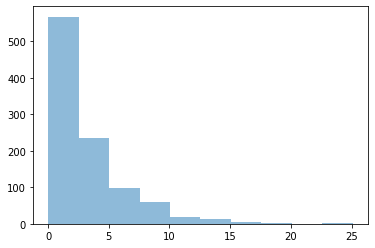

In [86]:
_ = plt.hist(est_theta_one, label='estimator=one', bins=10, alpha=0.5)

In [87]:
est_theta_one.var()

np.float64(9.840639304328658)

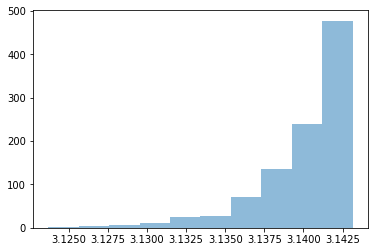

In [88]:
_ = plt.hist(est_theta_two, label='estimator=two', bins=10, alpha=0.5)

In [89]:
est_theta_two.var()

np.float64(9.239261016645378e-06)

# Consistency

In [95]:
from tqdm import tqdm

var_one = []
var_two = []


for n in tqdm(range(10, 1001, 10)):
    N = 2000

    x = np.random.rand(N, n) * theta
    
    est_theta_one = (n + 1) * x.min(axis=1)
    est_theta_two = (1 + 1 / n) * x.max(axis=1)
    
    var_one.append(est_theta_one.std())
    var_two.append(est_theta_two.std())

100%|██████████| 100/100 [00:00<00:00, 204.32it/s]


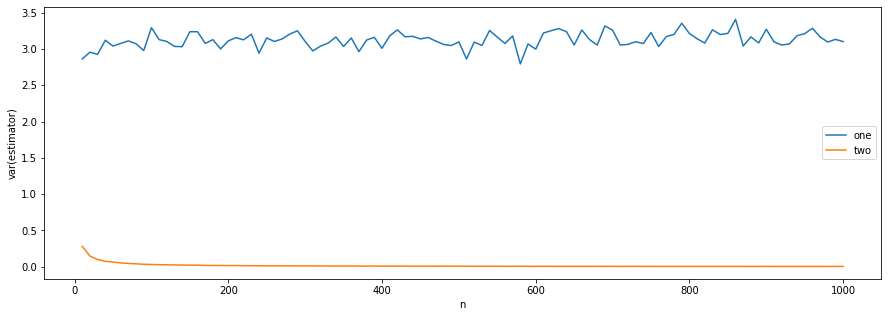

In [96]:
plt.figure(figsize=(15, 5))

_ = plt.plot(range(10, 1001, 10), var_one, label='one')
_ = plt.plot(range(10, 1001, 10), var_two, label='two')
plt.xlabel("n")
plt.ylabel("var(estimator)")
plt.legend()

100it [00:00, 196.36it/s]


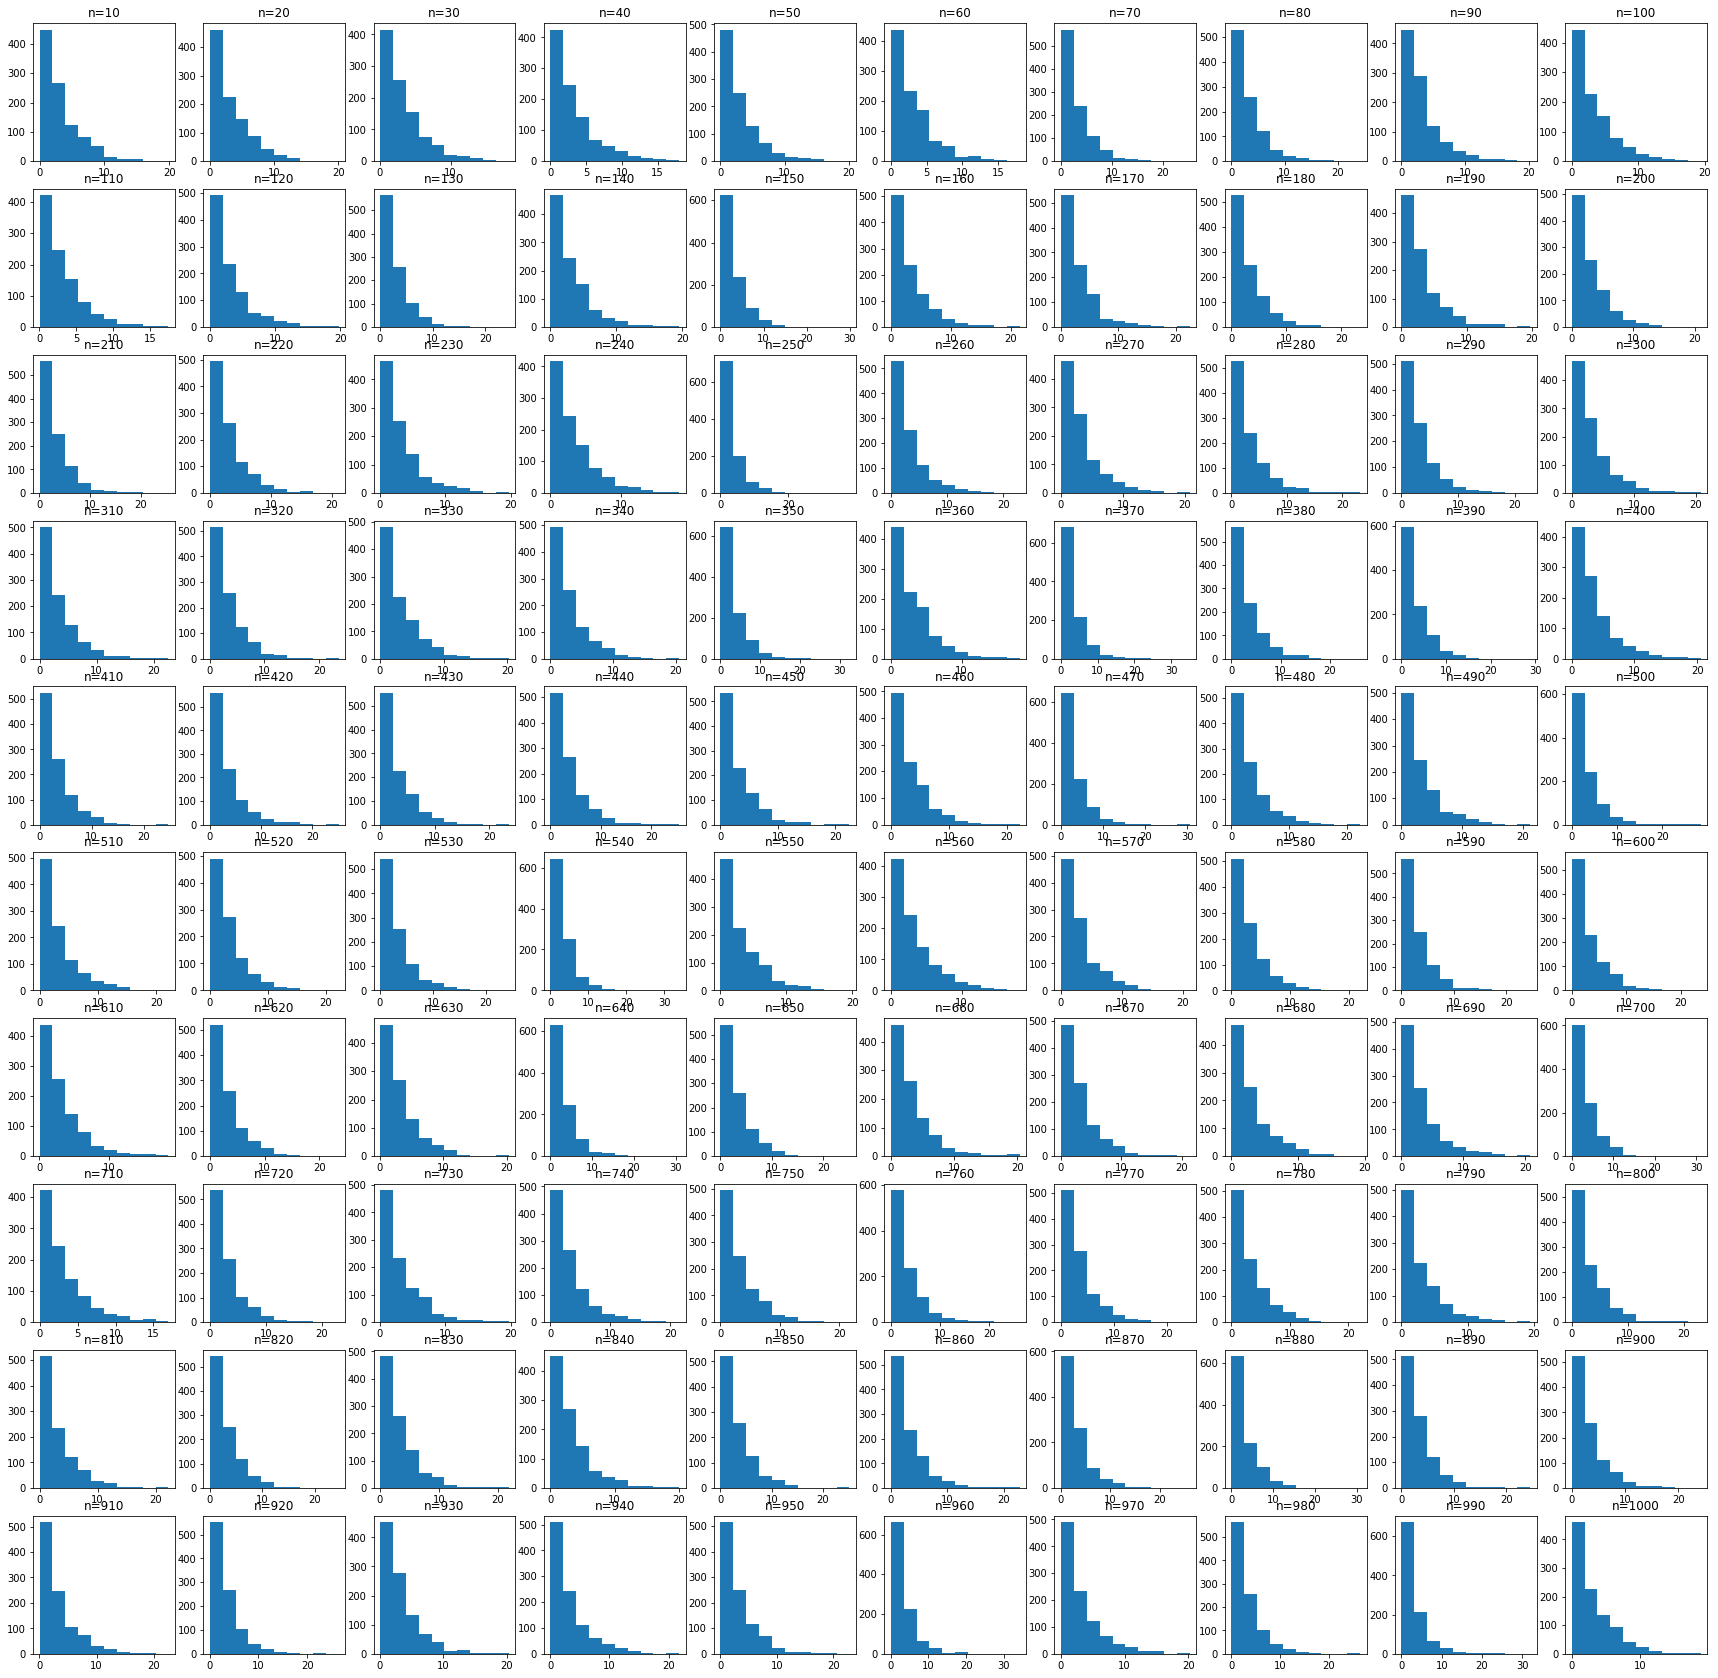

In [100]:
from tqdm import tqdm

var_one = []
var_two = []

fig, ax = plt.subplots(10, 10, figsize=(30, 30))

for k, n in tqdm(enumerate(range(10, 1001, 10))):
    N = 1000

    x = np.random.rand(N, n) * theta
    
    est_theta_one = (n + 1) * x.min(axis=1)
    est_theta_two = (1 + 1 / n) * x.max(axis=1)
    
    ax[k // 10, k % 10].hist(est_theta_one)
    ax[k // 10, k % 10].set_title("n={}".format(n))    

100it [00:00, 192.70it/s]


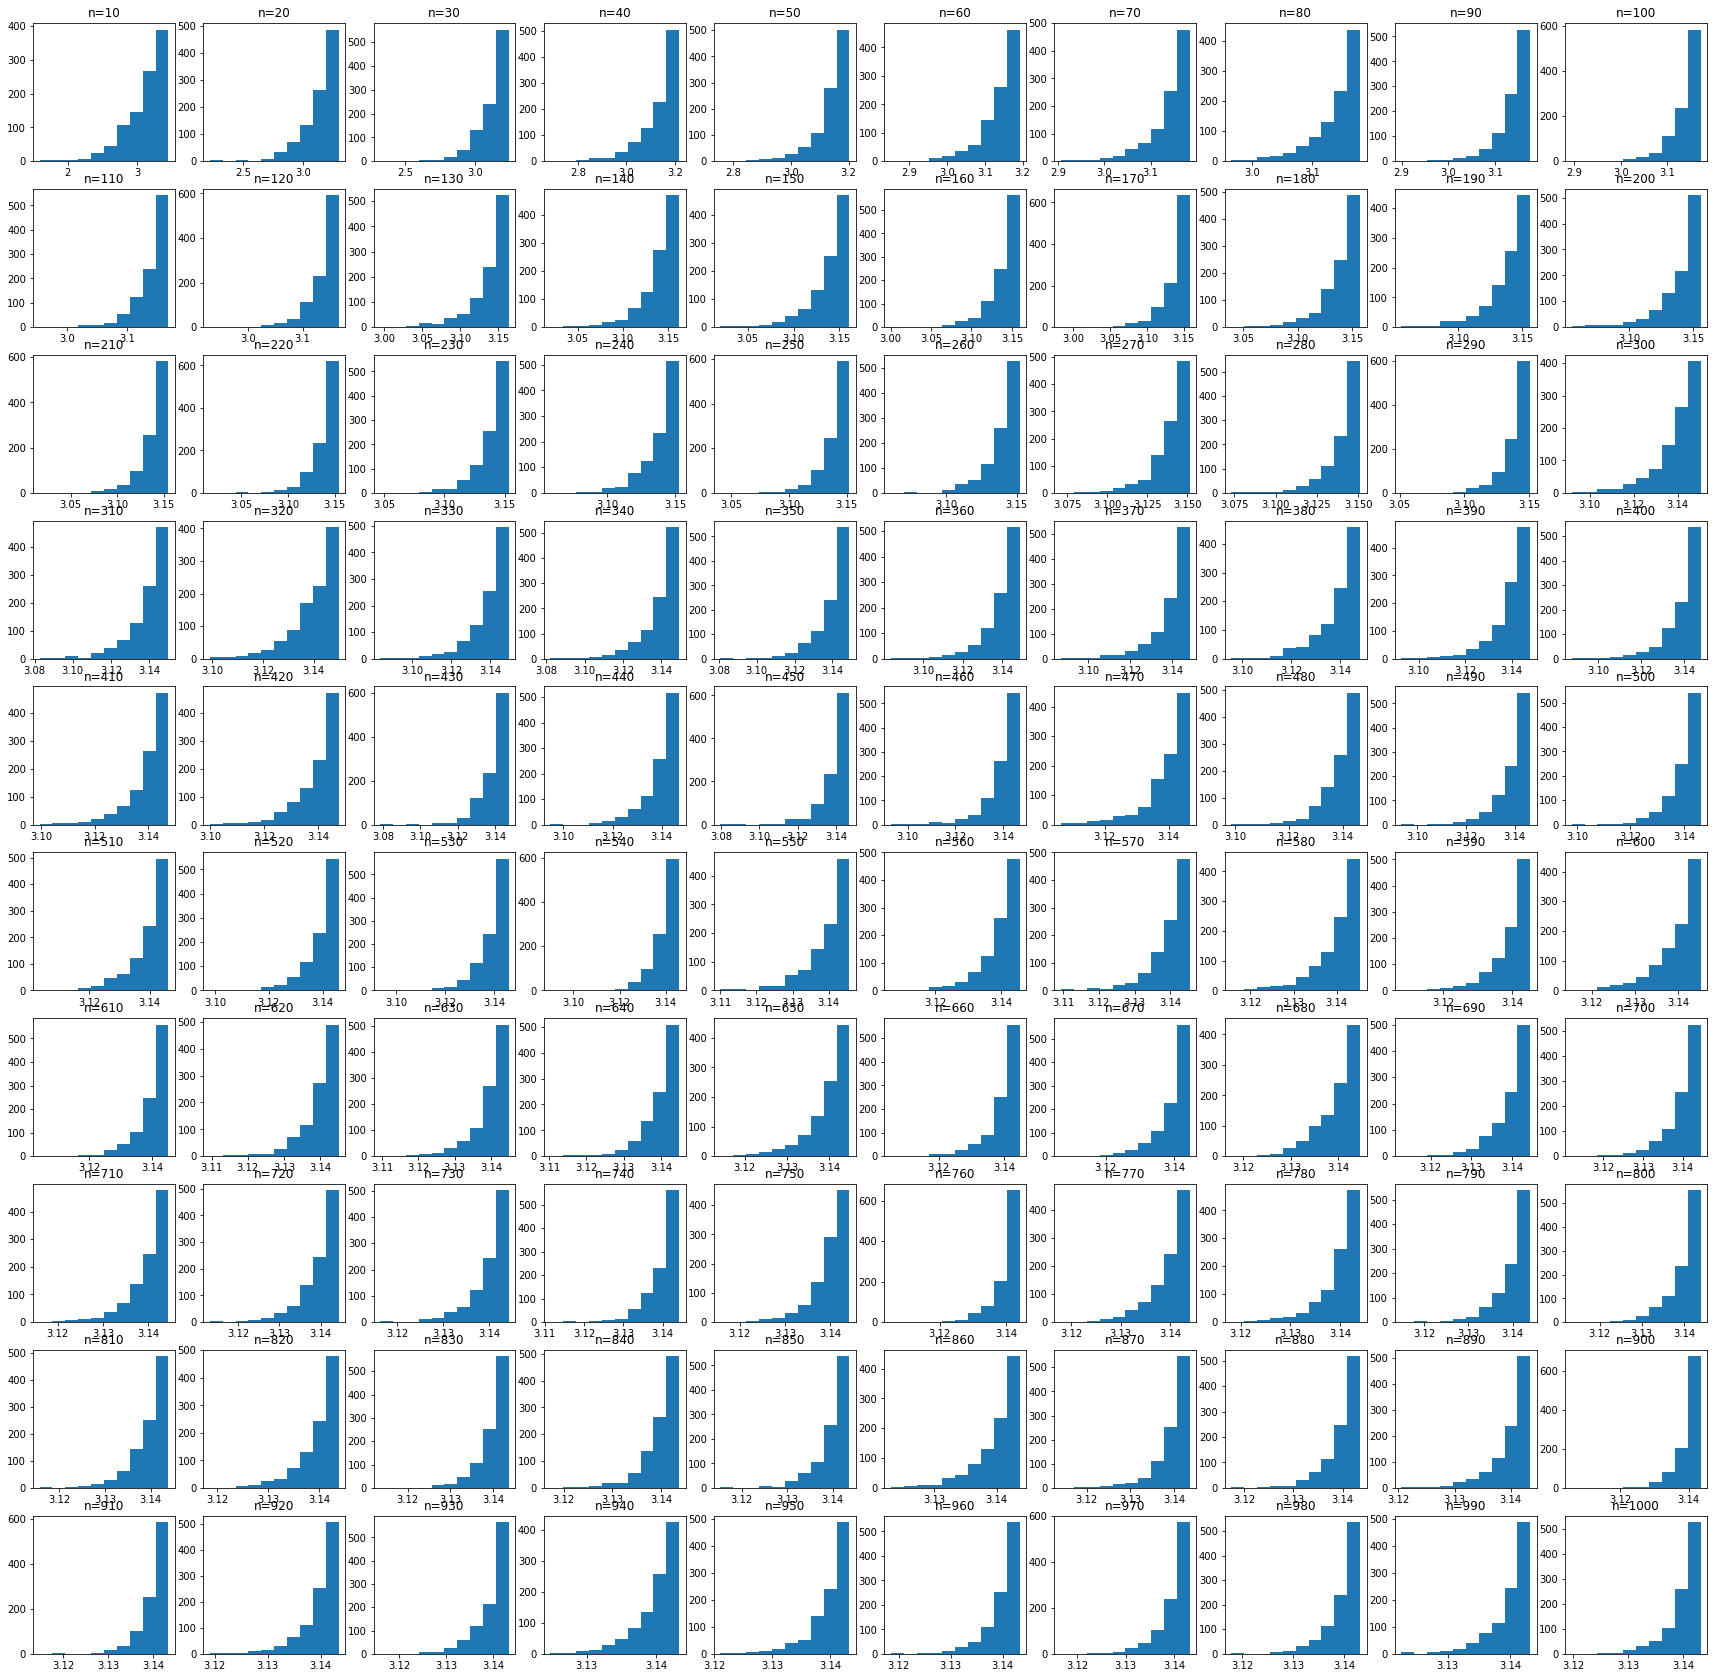

In [101]:
from tqdm import tqdm

var_one = []
var_two = []

fig, ax = plt.subplots(10, 10, figsize=(30, 30))

for k, n in tqdm(enumerate(range(10, 1001, 10))):
    N = 1000

    x = np.random.rand(N, n) * theta
    
    est_theta_one = (n + 1) * x.min(axis=1)
    est_theta_two = (1 + 1 / n) * x.max(axis=1)
    
    ax[k // 10, k % 10].hist(est_theta_two)
    ax[k // 10, k % 10].set_title("n={}".format(n))    

# Probalem A3, page 6

(array([60., 29.,  7.,  2.,  0.,  0.,  0.,  1.,  0.,  1.]),
 array([0.0075636 , 0.23510174, 0.46263987, 0.69017801, 0.91771614,
        1.14525428, 1.37279241, 1.60033055, 1.82786868, 2.05540682,
        2.28294495]),
 <BarContainer object of 10 artists>)

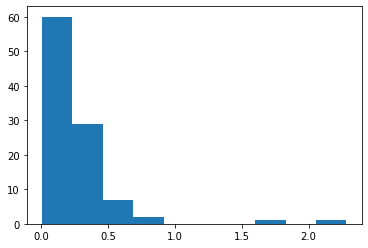

In [103]:
n = 100

theta = 1 / 3.14

x = np.random.exponential(theta, size=n)
plt.hist(x)

In [105]:
x.mean(), theta

(np.float64(0.25390592841501064), 0.3184713375796178)

## Незміщенність

In [112]:
n = 100
N = 1000

x =  np.random.exponential(theta, size=(N, n))
x.shape

estimators = x.mean(axis=1)

(array([  8.,  50., 121., 218., 285., 175.,  97.,  38.,   6.,   2.]),
 array([0.22829181, 0.24918138, 0.27007095, 0.29096052, 0.3118501 ,
        0.33273967, 0.35362924, 0.37451882, 0.39540839, 0.41629796,
        0.43718753]),
 <BarContainer object of 10 artists>)

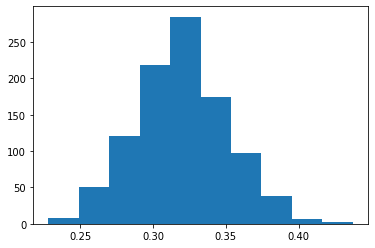

In [113]:
plt.hist(estimators)

In [115]:
estimators.mean(), theta

(np.float64(0.31972411973156956), 0.3184713375796178)

### Consistency

In [120]:

from tqdm import tqdm

var_one = []
var_two = []


for n in tqdm(range(10, 1001, 10)):
    N = 1000

    x = np.random.exponential(theta, size=(N, n))
    
    est_theta_one = x.mean(axis=1)
    
    var_one.append(est_theta_one.std())

100%|██████████| 100/100 [00:00<00:00, 203.18it/s]


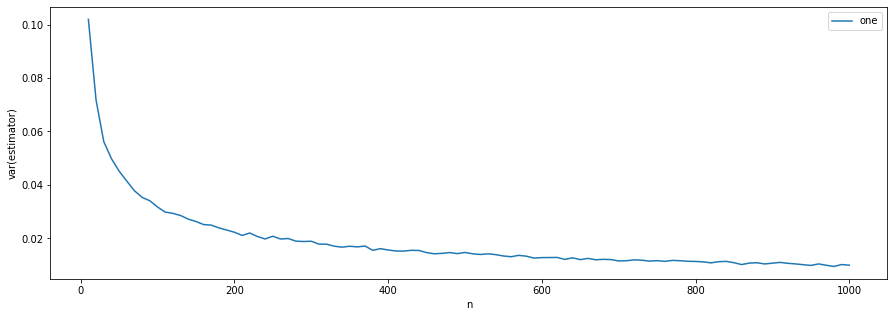

In [122]:

plt.figure(figsize=(15, 5))

_ = plt.plot(range(10, 1001, 10), var_one, label='one')
plt.xlabel("n")
plt.ylabel("var(estimator)")
plt.legend()

# Normality

In [130]:
from scipy.stats import norm

100it [00:01, 82.90it/s]


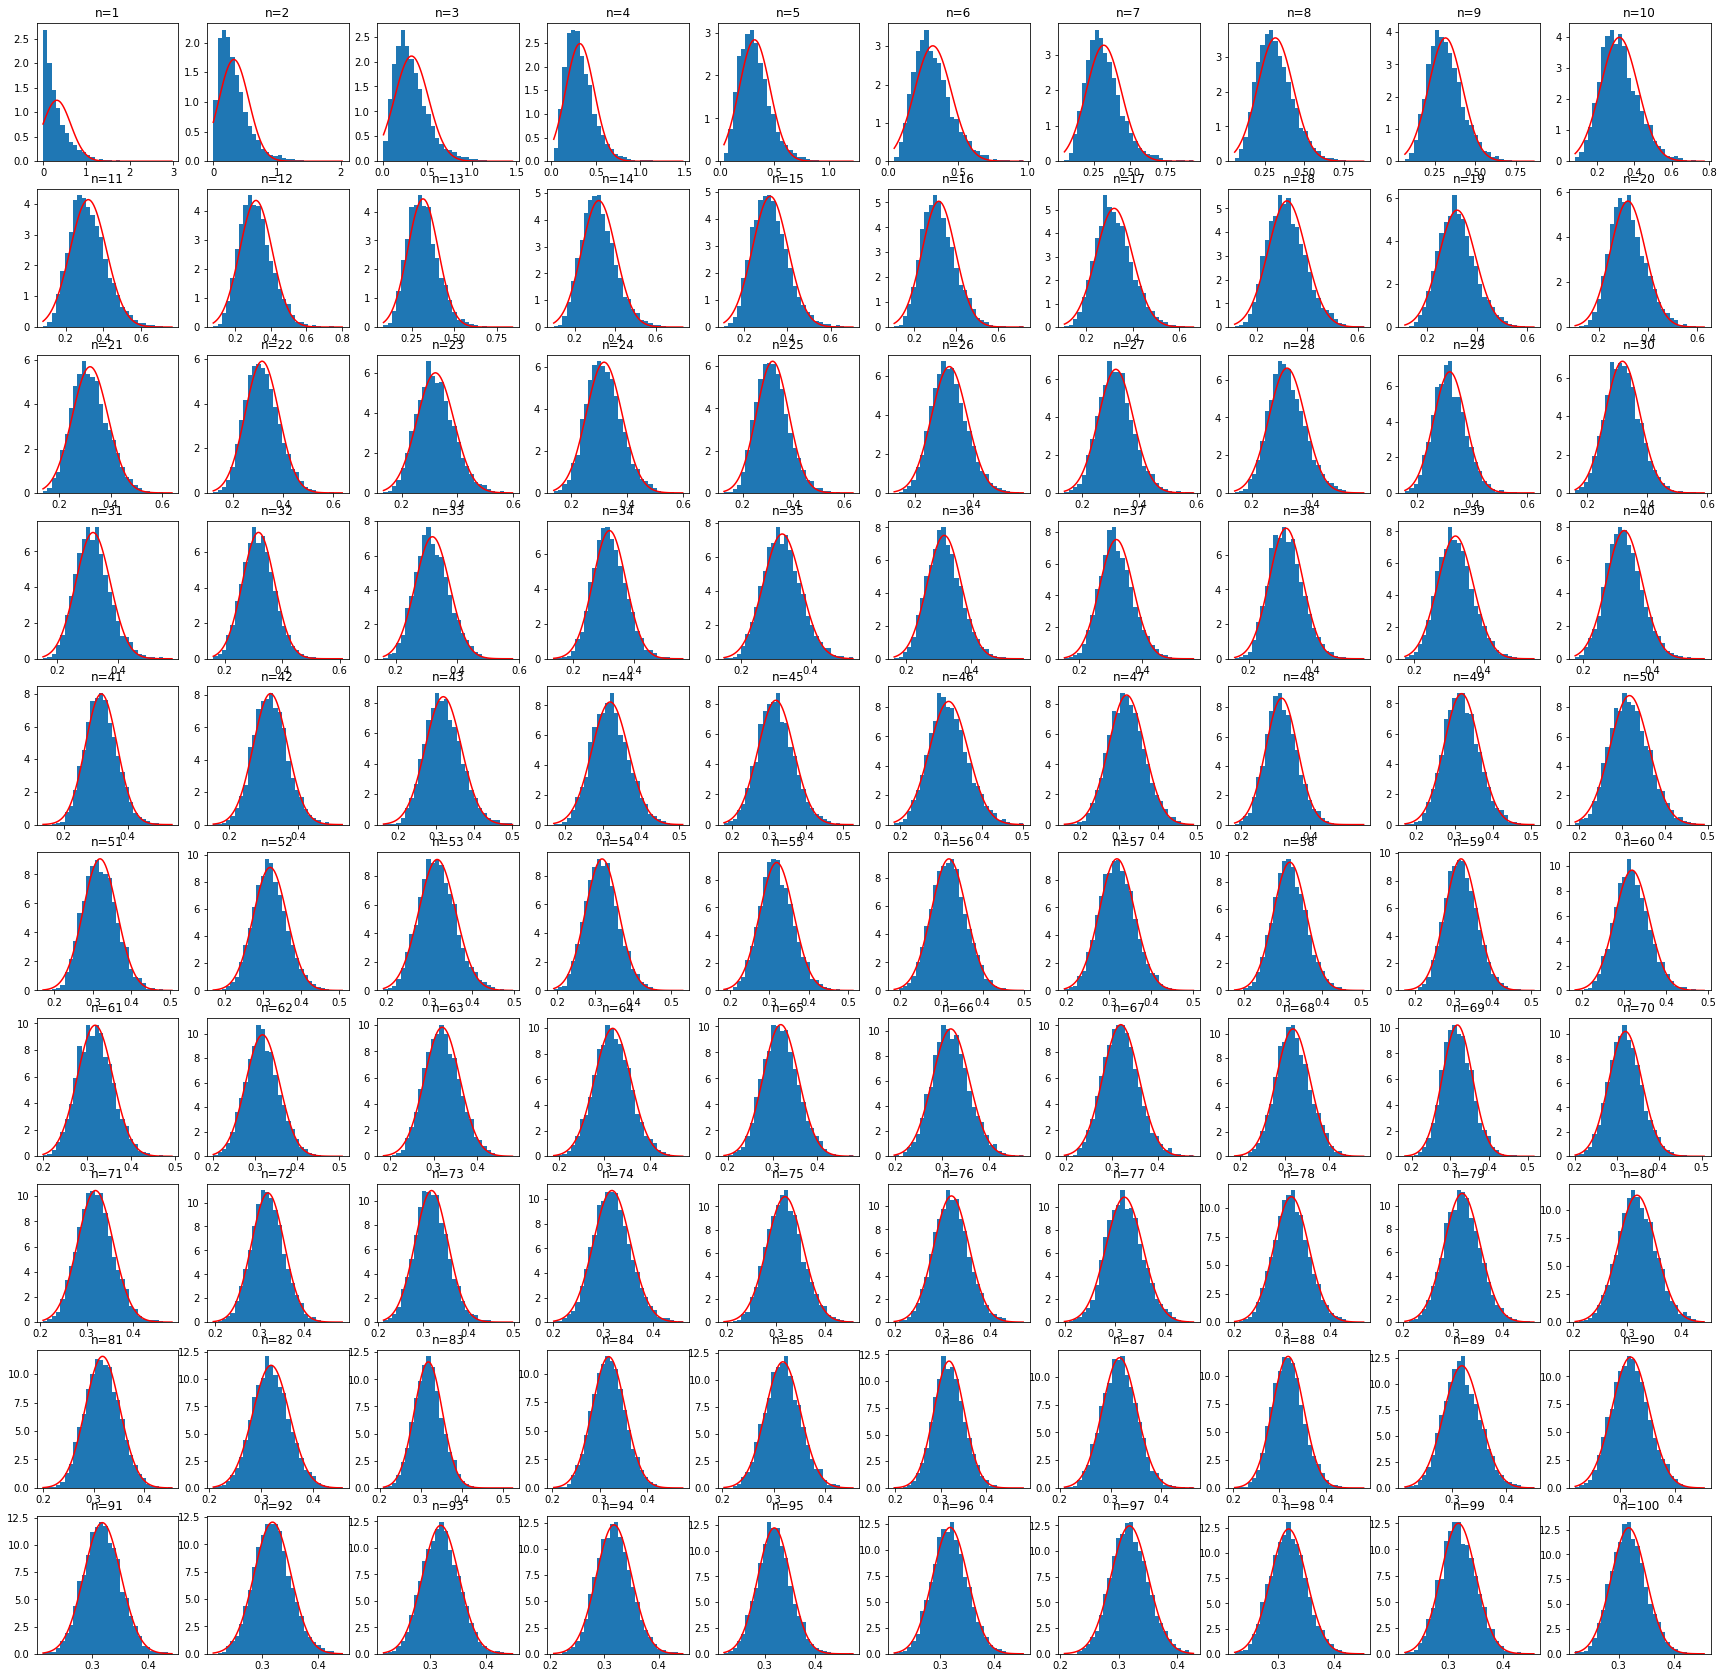

In [133]:
from tqdm import tqdm

var_one = []

fig, ax = plt.subplots(10, 10, figsize=(30, 30))

for k, n in tqdm(enumerate(range(1, 101, 1))):
    N = 5000


    x = np.random.exponential(theta, size=(N, n))
    
    est_theta_one = x.mean(axis=1)
    
    t = np.linspace(est_theta_one.min(), est_theta_one.max(), 100)
    
    ax[k // 10, k % 10].hist(est_theta_one, bins=30, density=True)
    ax[k // 10, k % 10].set_title("n={}".format(n))  
    ax[k // 10, k % 10].plot(t, norm(est_theta_one.mean(), est_theta_one.std()).pdf(t), color='red')

# Problem C11, page 9

In [137]:
import numpy as np
from matplotlib import pyplot as plt

theta = 3.14

M = 4
k = 250
N = 1000
n = M * k

x = np.random.rand(N, n) * theta

In [141]:
estimators = (x.min(axis=1) * (n + 1))

(array([467., 260., 130.,  56.,  39.,  26.,  15.,   4.,   1.,   2.]),
 array([6.21468132e-04, 1.99470762e+00, 3.98879377e+00, 5.98287993e+00,
        7.97696608e+00, 9.97105223e+00, 1.19651384e+01, 1.39592245e+01,
        1.59533107e+01, 1.79473968e+01, 1.99414830e+01]),
 <BarContainer object of 10 artists>)

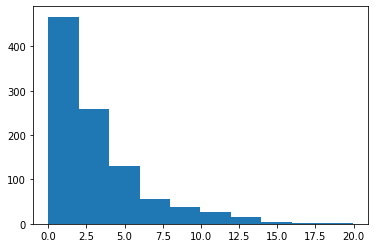

In [143]:
plt.hist(estimators)

In [147]:
x.reshape(N, k, M).shape

(1000, 250, 4)

In [152]:
ests = (x.reshape(N, k, M).min(axis=2) * (M + 1))

In [ ]:
plt.hist(ests[0])

In [156]:
ests.mean(axis=1)

(1000,)

(array([  4.,  11.,  33., 156., 241., 272., 183.,  84.,  14.,   2.]),
 array([2.52947045, 2.64646581, 2.76346116, 2.88045651, 2.99745186,
        3.11444721, 3.23144257, 3.34843792, 3.46543327, 3.58242862,
        3.69942397]),
 <BarContainer object of 10 artists>)

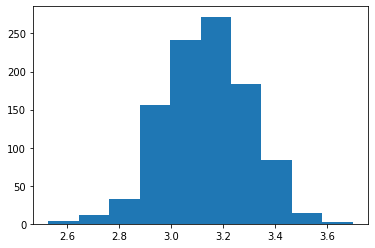

In [157]:
plt.hist(ests.mean(axis=1))

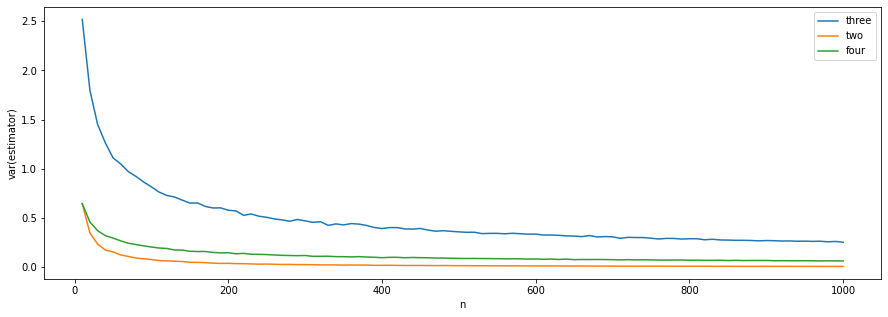

In [175]:
from tqdm import tqdm

var_three = []
var_two = []

var_four = []

for k in range(1, 101, 1):
    N = 2000
    
    M = 4
    n = M * k
    
    x = np.random.rand(N, n) * theta
    
    est_theta_three = (x.reshape(N, k, M).min(axis=2) * (M + 1)).mean(axis=1)
    est_theta_four = (x.reshape(N, k, M).max(axis=2) * (1 + 1 / M)).mean(axis=1)

    est_theta_two = (1 + 1 / n) * x.max(axis=1)
    
    var_three.append(est_theta_three.std())
    var_two.append(est_theta_two.std())
    var_four.append(est_theta_four.std())
    
plt.figure(figsize=(15, 5))

_ = plt.plot(range(10, 1001, 10), var_three, label='three')
_ = plt.plot(range(10, 1001, 10), var_two, label='two')
_ = plt.plot(range(10, 1001, 10), var_four, label='four')

plt.xlabel("n")
plt.ylabel("var(estimator)")
plt.legend()

In [176]:
est_theta_three

array([2.91902895, 3.03922893, 2.96156153, ..., 3.43412883, 3.08069536,
       3.18724277], shape=(2000,))

100it [00:00, 194.06it/s]


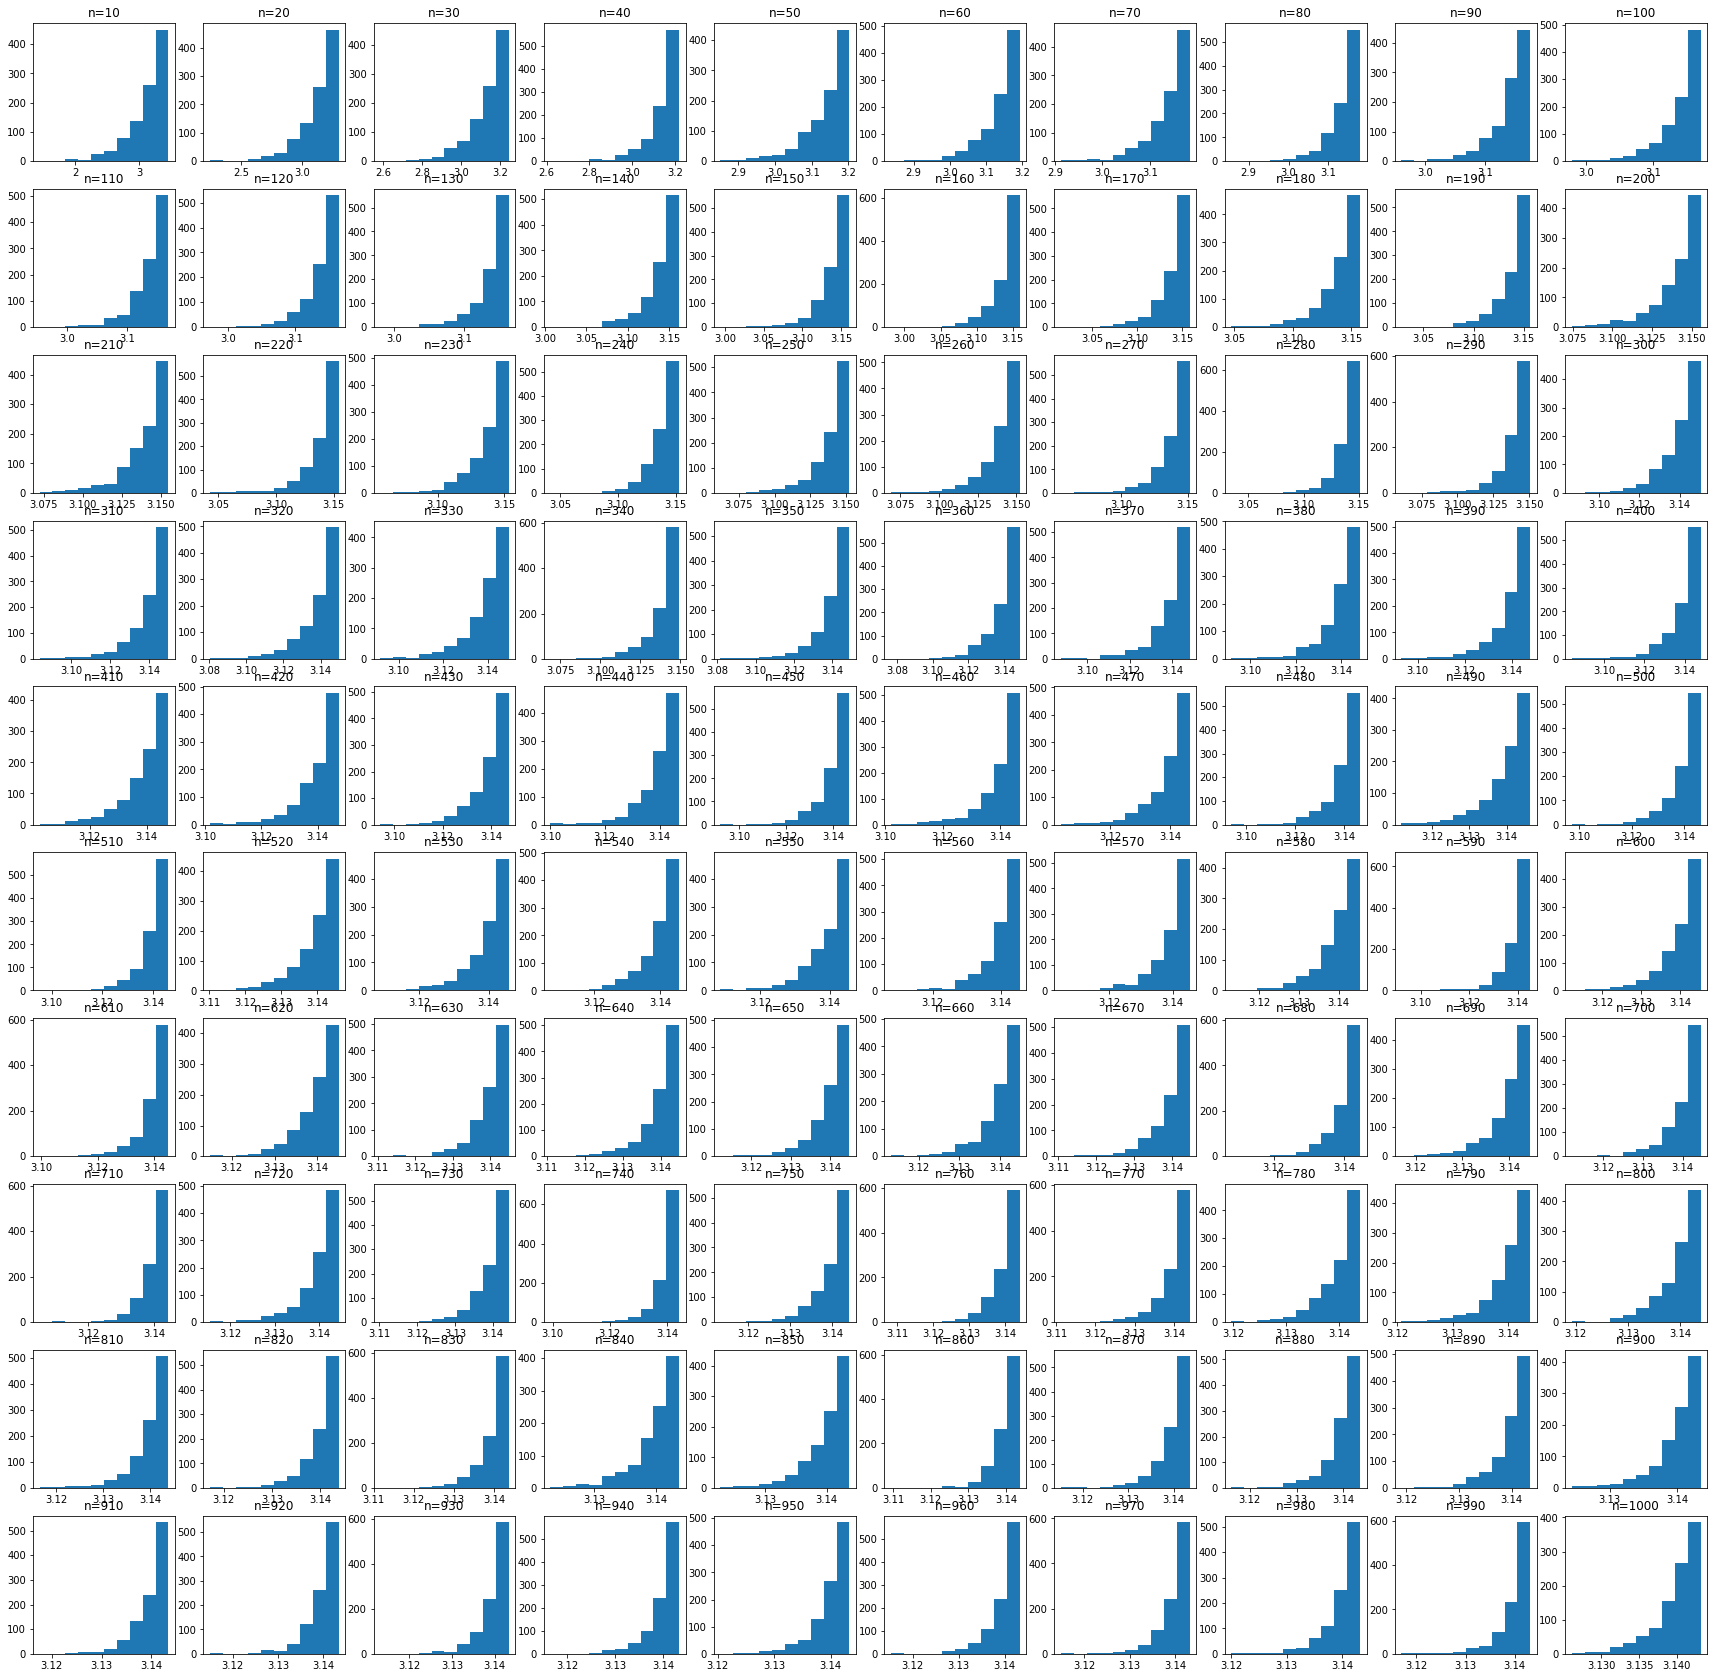

In [161]:
from tqdm import tqdm

var_one = []
var_two = []

fig, ax = plt.subplots(10, 10, figsize=(30, 30))

for k, n in tqdm(enumerate(range(10, 1001, 10))):
    N = 1000

    x = np.random.rand(N, n) * theta
    
    est_theta_one = (n + 1) * x.min(axis=1)
    est_theta_two = (1 + 1 / n) * x.max(axis=1)
    
    ax[k // 10, k % 10].hist(est_theta_two)
    ax[k // 10, k % 10].set_title("n={}".format(n))    

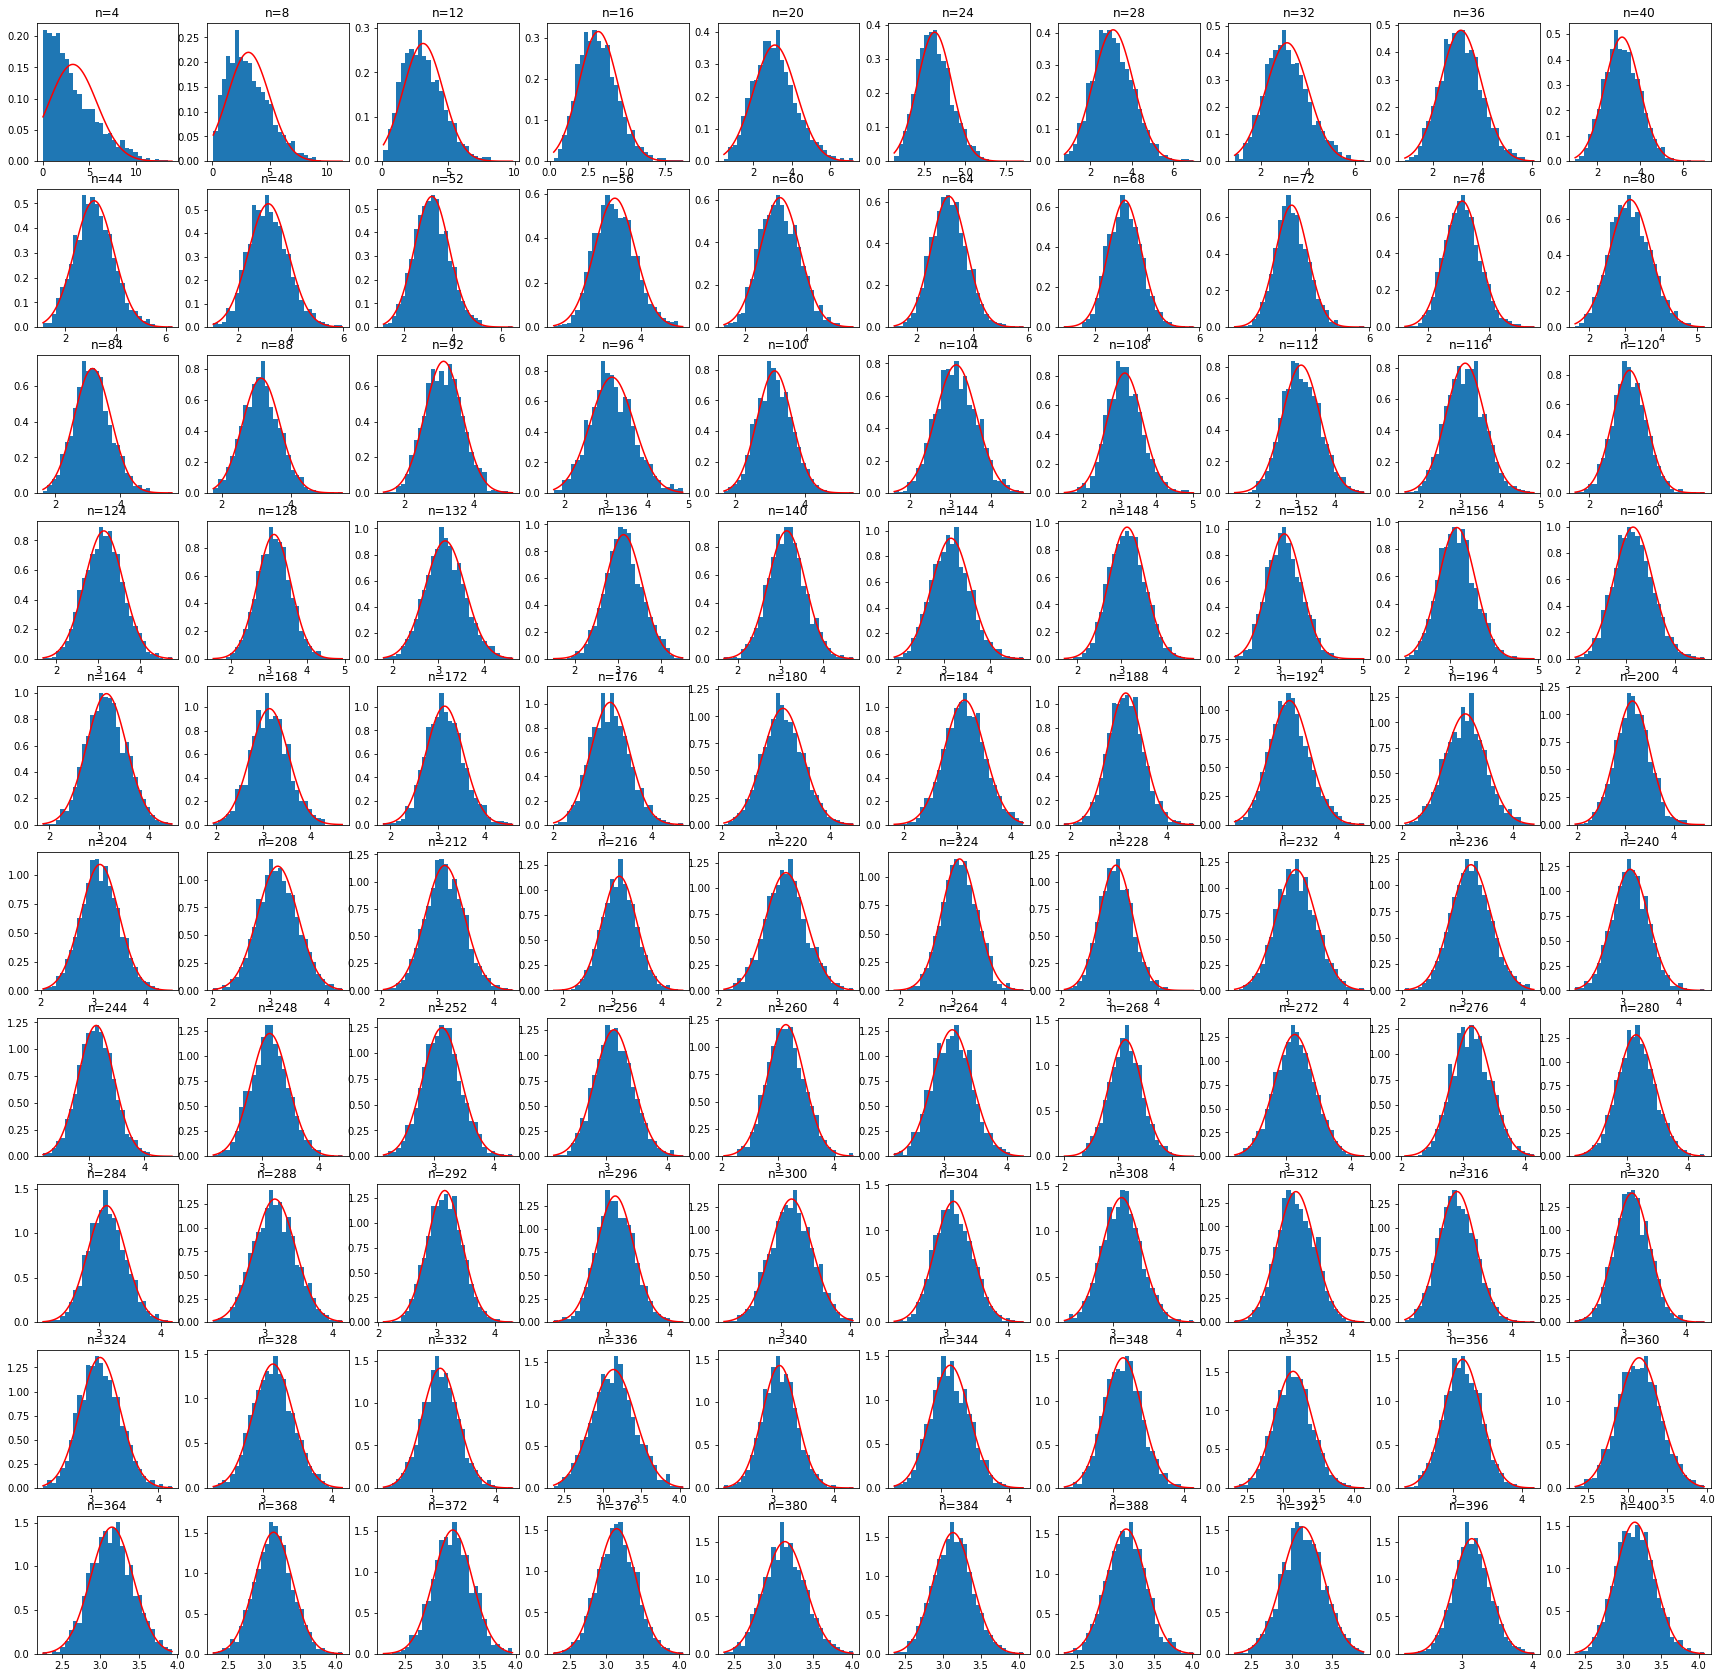

In [170]:
from tqdm import tqdm

var_one = []
var_two = []

fig, ax = plt.subplots(10, 10, figsize=(30, 30))

for kk, k in enumerate(range(1, 101, 1)):
    N = 2000
    
    M = 4
    n = M * k
    
    x = np.random.rand(N, n) * theta
    
    est_theta_three = (x.reshape(N, k, M).min(axis=2) * (M + 1)).mean(axis=1)

    t = np.linspace(est_theta_three.min(), est_theta_three.max(), 100)
    
    ax[kk // 10, kk % 10].hist(est_theta_three, density=True, bins=30)
    ax[kk // 10, kk % 10].set_title("n={}".format(n))
    ax[kk // 10, kk % 10].plot(t, norm(est_theta_three.mean(), est_theta_three.std()).pdf(t), color='red')

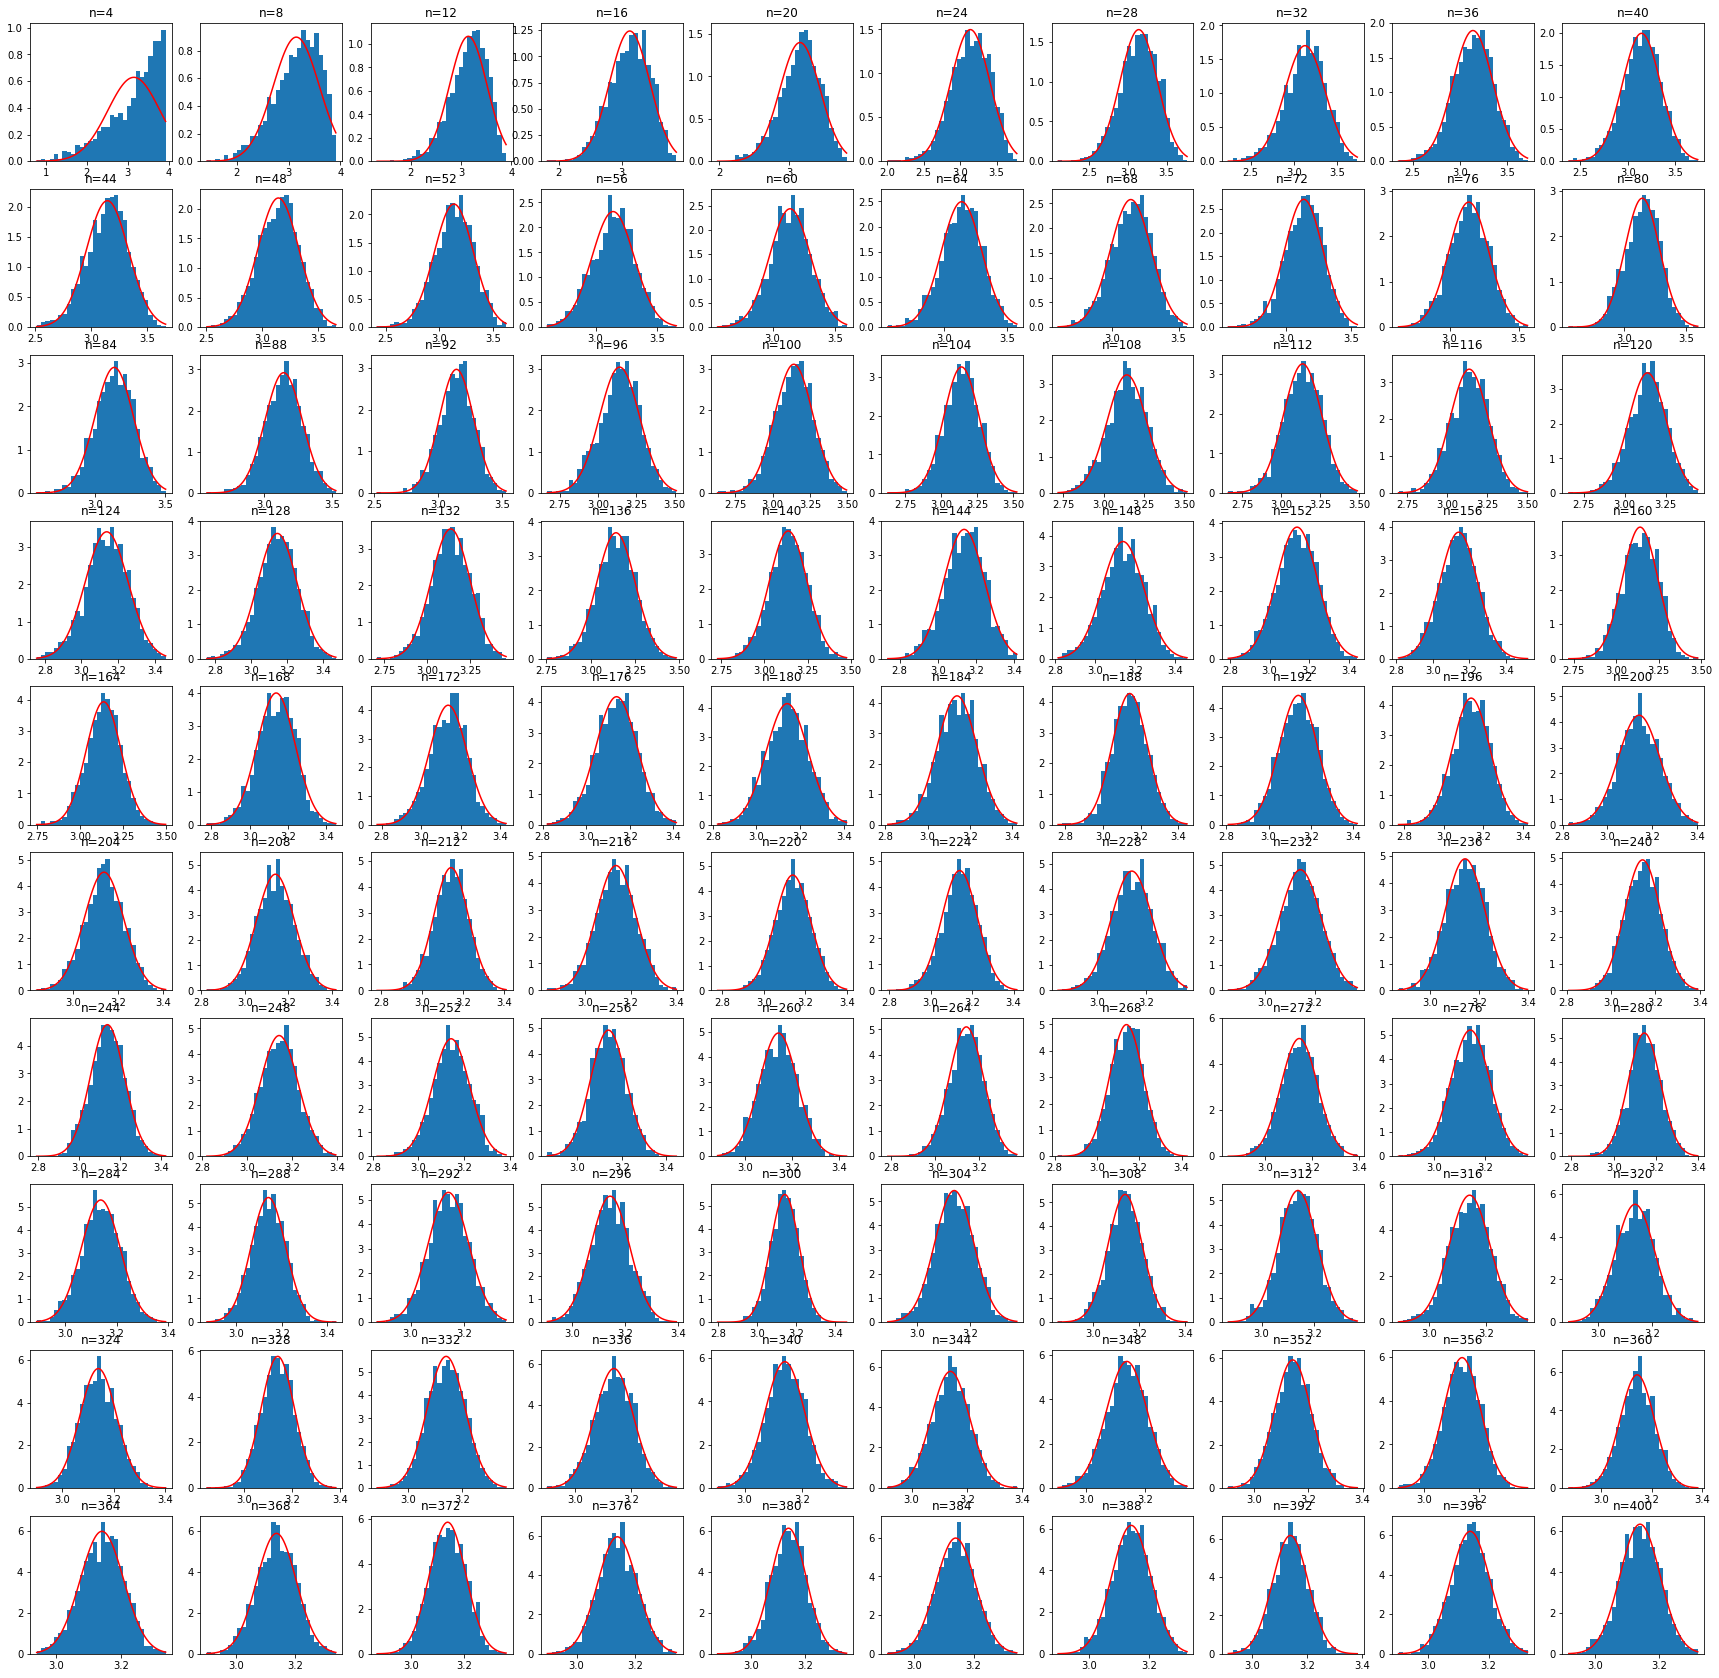

In [177]:
from tqdm import tqdm

var_one = []
var_two = []

fig, ax = plt.subplots(10, 10, figsize=(30, 30))

for kk, k in enumerate(range(1, 101, 1)):
    N = 2000
    
    M = 4
    n = M * k
    
    x = np.random.rand(N, n) * theta
    
#     est_theta_three = (x.reshape(N, k, M).min(axis=2) * (M + 1)).mean(axis=1)
    est_theta_four = (x.reshape(N, k, M).max(axis=2) * (1 + 1 / M)).mean(axis=1)
    
    t = np.linspace(est_theta_four.min(), est_theta_four.max(), 100)
    
    ax[kk // 10, kk % 10].hist(est_theta_four, density=True, bins=30)
    ax[kk // 10, kk % 10].set_title("n={}".format(n))
    ax[kk // 10, kk % 10].plot(t, norm(est_theta_four.mean(), est_theta_four.std()).pdf(t), color='red')